In [4]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

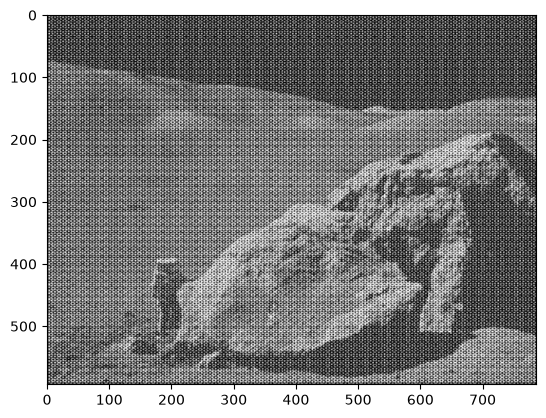

In [5]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

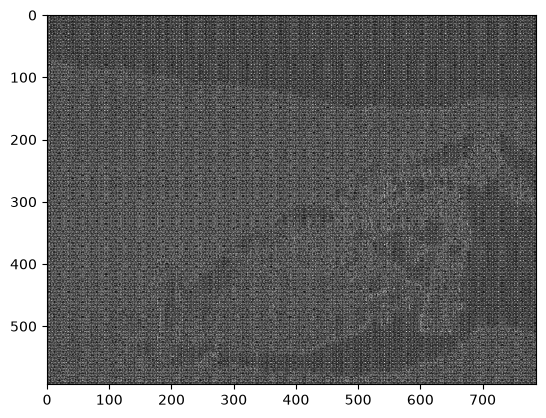

In [6]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

rows, cols = img.shape
cy, cx = rows // 2, cols // 2
sigma = 20

Y, X = np.meshgrid(np.arange(rows), np.arange(cols), indexing='ij')
gauss_lp = np.exp(-((X - cx)**2 + (Y - cy)**2) / (2 * sigma**2))
hp_mask  = 1.0 - gauss_lp

dft_hp = dft_shift * hp_mask[:, :, np.newaxis]
image_idft = cv.idft(np.fft.ifftshift(dft_hp))
image_idft = cv.magnitude(image_idft[:, :, 0], image_idft[:, :, 1])

plt.imshow(image_idft, cmap='gray')

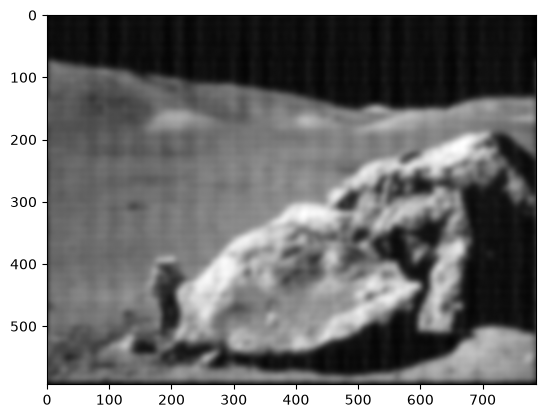

In [7]:
# Реализуйте вычисление свертки с помощью преобразования Фурье
ksize   = 31
sigma_k = 5.0
g1d    = cv.getGaussianKernel(ksize, sigma_k)
kernel = np.outer(g1d, g1d)

H, W = img.shape

kernel_padded = np.zeros((H, W), dtype=np.float32)
kh, kw = kernel.shape
kernel_padded[:kh, :kw] = kernel

kernel_padded = np.roll(kernel_padded, -kh // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -kw // 2, axis=1)

F_img    = np.fft.fft2(img.astype(np.float32))
F_kernel = np.fft.fft2(kernel_padded)
img_conv_fft = np.real(np.fft.ifft2(F_img * F_kernel))

plt.imshow(img_conv_fft, cmap='gray')

C:\Users\user\AppData\Local\Temp\ipykernel_22024\558075656.py:9: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))


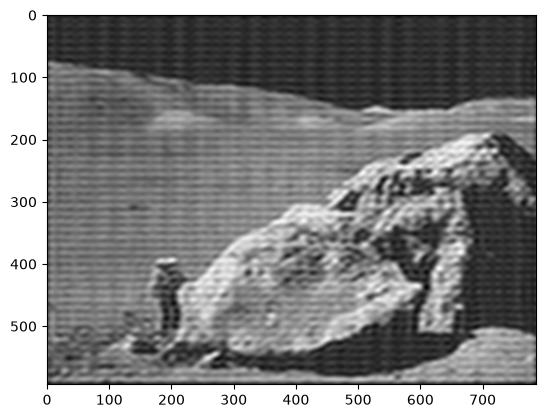

In [8]:
# Реализуйте удаление периодического шума с помощью преобразования Фурье
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

dft_shift = dft_shift*mask
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

plt.imshow(img_back, cmap = 'gray')
plt.show()

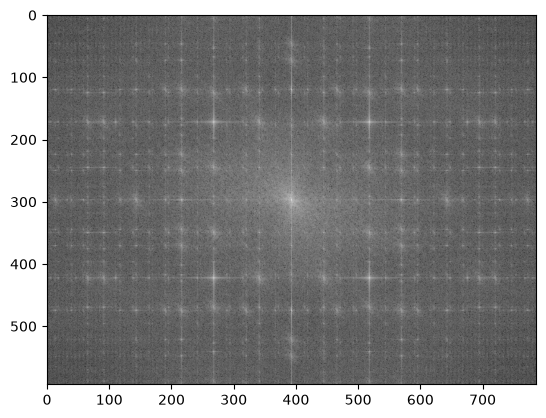

In [13]:
plt.imshow(magnitude_spectrum, cmap='gray')